# Final Model Evaluation

This notebook performs the final evaluation of the trained
Autoencoder-based credit card fraud detection system.

Objectives:
- Verify the final dataset and saved model artifacts
- Reproduce the prototype's anomaly detection results
- Calculate the final confusion matrix and evaluation metrics
- Analyze the effect of anomaly-score thresholds
- Compare the Autoencoder with Isolation Forest
- Generate final results and figures for the research paper

In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import joblib
import json

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# Load the final cleaned dataset

data = pd.read_csv(
    "../data/processed/creditcard_clean.csv"
)

print("Dataset loaded successfully.")
print("Rows:", len(data))
print("Columns:", len(data.columns))

print("\nClass distribution:")
print(data["Class"].value_counts())

Dataset loaded successfully.
Rows: 284807
Columns: 31

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [3]:
# Load the anomaly detection threshold

with open("../models/threshold.json", "r") as f:
    threshold = json.load(f)["threshold"]

print("Final threshold:", threshold)

Final threshold: 4.7944


In [4]:
# Load the exact trained Autoencoder and scaler

import tensorflow as tf
import joblib

autoencoder = tf.keras.models.load_model(
    "../models/autoencoder.keras"
)

scaler = joblib.load(
    "../models/scaler.pkl"
)

print("Autoencoder loaded successfully.")
print("Model input shape:", autoencoder.input_shape)
print("Model output shape:", autoencoder.output_shape)
print("Scaler feature count:", scaler.n_features_in_)

Autoencoder loaded successfully.
Model input shape: (None, 30)
Model output shape: (None, 30)
Scaler feature count: 30


In [5]:
# Generate anomaly scores for every transaction

features = data.drop(columns=["Class"])

# Scale all transactions
scaled_features = scaler.transform(features)

# Reconstruct transactions using Autoencoder
reconstructed = autoencoder.predict(
    scaled_features,
    verbose=0
)

# Calculate reconstruction error
reconstruction_errors = (
    (scaled_features - reconstructed) ** 2
).mean(axis=1)

# Convert scores into predictions
predictions = (
    reconstruction_errors > threshold
).astype(int)

print("Evaluation completed.")
print("Total transactions:", len(predictions))
print("Total anomalies detected:", predictions.sum())

Evaluation completed.
Total transactions: 284807
Total anomalies detected: 1562


In [6]:
from sklearn.metrics import confusion_matrix

y_true = data["Class"].values

tn, fp, fn, tp = confusion_matrix(
    y_true,
    predictions
).ravel()

print("Confusion Matrix Results")
print("------------------------")
print("True Negatives  (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives  (TP):", tp)

Confusion Matrix Results
------------------------
True Negatives  (TN): 283102
False Positives (FP): 1213
False Negatives (FN): 143
True Positives  (TP): 349


In [7]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

precision = precision_score(y_true, predictions, zero_division=0)
recall = recall_score(y_true, predictions, zero_division=0)
f1 = f1_score(y_true, predictions, zero_division=0)

roc_auc = roc_auc_score(
    y_true,
    reconstruction_errors
)

pr_auc = average_precision_score(
    y_true,
    reconstruction_errors
)

fpr = fp / (fp + tn)

print("FINAL AUTOENCODER RESULTS")
print("==========================")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"FPR       : {fpr:.6f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

FINAL AUTOENCODER RESULTS
Precision : 0.2234
Recall    : 0.7093
F1 Score  : 0.3398
FPR       : 0.004266
ROC-AUC   : 0.9602
PR-AUC    : 0.3712


In [8]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        predictions,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    284315
       Fraud       0.22      0.71      0.34       492

    accuracy                           1.00    284807
   macro avg       0.61      0.85      0.67    284807
weighted avg       1.00      1.00      1.00    284807



In [9]:
fraud_indices = np.where(predictions == 1)[0]

actual_fraud_detected = data.loc[
    fraud_indices,
    "Class"
].sum()

actual_fraud_total = data["Class"].sum()

print("Total anomalies detected:", len(fraud_indices))
print("Actual fraud transactions:", int(actual_fraud_total))
print("Frauds correctly detected:", int(actual_fraud_detected))
print("Frauds missed:", int(actual_fraud_total - actual_fraud_detected))

Total anomalies detected: 1562
Actual fraud transactions: 492
Frauds correctly detected: 349
Frauds missed: 143


In [10]:
print("First 20 detected anomaly indices:")

print(
    fraud_indices[:20]
)

First 20 detected anomaly indices:
[1388 1632 2792 3099 3761 4895 5425 5534 5535 5791 5916 6095 6108 6300
 6305 6306 6329 6331 6334 6336]


In [11]:
detected_transactions = data.iloc[
    fraud_indices[:20]
].copy()

detected_transactions[
    ["Time", "Amount", "Class"]
]

,Time,Amount,Class
1388,1077.0,2452.03,0
1632,1264.0,7712.43,0
2792,2341.0,85.00,0
3099,2656.0,121.00,0
3761,3254.0,0.89,0
4895,4429.0,0.77,0
5425,5406.0,553.60,0
5534,5618.0,5.49,0
5535,5619.0,1.98,0
5791,6210.0,47.57,0


In [12]:
threshold_percentiles = [95, 99, 99.5, 99.9]

threshold_results = []

for percentile in threshold_percentiles:

    current_threshold = np.percentile(
        reconstruction_errors,
        percentile
    )

    current_predictions = (
        reconstruction_errors > current_threshold
    ).astype(int)

    current_tn, current_fp, current_fn, current_tp = (
        confusion_matrix(
            y_true,
            current_predictions
        ).ravel()
    )

    current_precision = precision_score(
        y_true,
        current_predictions,
        zero_division=0
    )

    current_recall = recall_score(
        y_true,
        current_predictions,
        zero_division=0
    )

    current_f1 = f1_score(
        y_true,
        current_predictions,
        zero_division=0
    )

    current_fpr = current_fp / (
        current_fp + current_tn
    )

    threshold_results.append({
        "Percentile": percentile,
        "Threshold": current_threshold,
        "TP": current_tp,
        "FP": current_fp,
        "FN": current_fn,
        "Precision": current_precision,
        "Recall": current_recall,
        "F1": current_f1,
        "FPR": current_fpr
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df

,Percentile,Threshold,TP,FP,FN,Precision,Recall,F1,FPR
0,95.0,1.104782,432,13809,60,0.030335,0.878049,0.058644,0.048569
1,99.0,2.835182,402,2447,90,0.141102,0.817073,0.240647,0.008607
2,99.5,5.136973,328,1097,164,0.230175,0.666667,0.342201,0.003858
3,99.9,22.816581,150,135,342,0.526316,0.304878,0.386100,0.000475


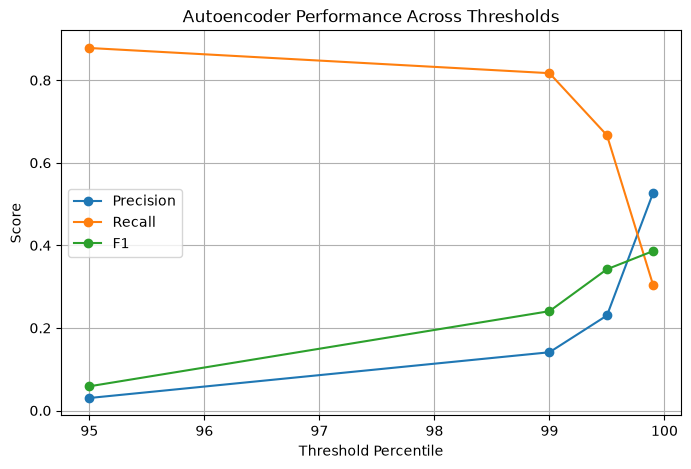

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Percentile"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Percentile"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Percentile"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Threshold Percentile")
plt.ylabel("Score")
plt.title("Autoencoder Performance Across Thresholds")
plt.legend()
plt.grid(True)

plt.show()

In [14]:
import os

print("Files in models folder:")

for file in os.listdir("../models"):
    print(file)

Files in models folder:
autoencoder.keras
scaler.pkl
threshold.json
